# List 2: Tokenization & Embeddings

Labs: Mon 19 Oct, Mon 26 Oct 2026 · Due: Sun 8 Nov 2026, 23:59 · 1 point

- For each task, show the requested numbers or plots and explain them in two to four sentences. The list is graded as a whole, in steps of 0.25, by how complete, correct and well explained your solution is.
- Data, code structure and names are up to you; defaults are given for when you have no preference. Keep the signatures of the two given definitions (`create_dataloader`, `GPTEmbedding`), because later lists reuse them (check them with Materials, Appendix A).
- Background and the Python and PyTorch functions you need for Task X.Y are in Materials X.Y.
- Submit this notebook run from top to bottom with outputs, or Python scripts with a PDF report of at most four pages (results and explanations per task). Late: −10% per day, 0 after 5 days.
- Tasks marked *(optional)* are not graded: the full point is available from the other tasks. They are there for depth and for project ideas. In exceptional cases the grader may take them into account, within the 1-point maximum.
- Individual work. Name the AI tools you used at the top of your solution.

**AI tools used:** Claude (Anthropic) — used to help write and explain the code.

The solutions follow the course *Materials for List 2* (`materials02.pdf`); each task cites the section it uses as **Materials X.Y**, and **Appendix A / B** for the reusable definitions and the checkpoints. The materials follow Raschka, *Build a Large Language Model (From Scratch)*, Sections 2.1–2.8, and Lecture 3; BPE is from Sennrich et al. (2016), sinusoidal encodings from Vaswani et al. (2017), skip-gram with negative sampling from Mikolov et al. (2013).

`the-verdict.txt` must be in the same folder as this notebook. The first call of `tiktoken.get_encoding("gpt2")` downloads GPT-2's vocabulary (Materials 0.2).

In [4]:
import tiktoken
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Dataset

Extra imports used throughout the notebook.

In [5]:
import math
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

text = Path("the-verdict.txt").read_text(encoding="utf-8")
n_train = int(0.9 * len(text))
train_text, held_text = text[:n_train], text[n_train:]     # first 90% / last 10% (Tasks 3.2-3.5)
enc = tiktoken.get_encoding("gpt2")                        # GPT-2's tokenizer (Materials 3.4)
print(len(text), "characters:", len(train_text), "for training,", len(held_text), "held out")

20479 characters: 18431 for training, 2048 held out


## Lab 3

### 3.1 A word tokenizer

Default text: `the-verdict.txt` (as in List 1). Tasks 3.2–3.5 use its first 90% for training and its last 10% as held-out text.

- Split the text with a regular expression that separates punctuation and whitespace, build the vocabulary from the whole text, and implement `encode` and `decode`. Reference: the regular expression of Materials 3.1 gives 1130 distinct tokens.
- Find a passage of the text for which `decode(encode(text)) != text` and explain which information the split discarded. Repair the spacing before punctuation in `decode` and say what still cannot be recovered.

**What I do** (background: Materials 3.1 — *Boundary rules*, *Vocabulary and lookup*, *Decoding cannot restore what the split discarded*)

1. Split the text with BLLM's regular expression `r'([,.:;?_!"()\']|--|\s)'`. Because the pattern is in a capturing group, `re.split` keeps the punctuation and whitespace pieces; I keep only the pieces with `t.strip()` non-empty, so words and punctuation remain and whitespace is dropped.
2. The vocabulary is the sorted set of tokens; `stoi` maps token → ID, `itos` ID → token.
3. `encode` = split + look up every token; `decode` = look up every ID + join with one space.
4. Run the round trip on the first paragraph of the text, then repair the spacing with BLLM's `re.sub(r'\s+([,.?!"()\'])', r'\1', s)`, which deletes whitespace before punctuation.

In [6]:
SPLIT = r'([,.:;?_!"()\']|--|\s)'

def split_words(s):
    return [t for t in re.split(SPLIT, s) if t.strip()]   # drop empty and whitespace pieces

vocab = sorted(set(split_words(text)))                    # vocabulary from the whole text
stoi = {tok: i for i, tok in enumerate(vocab)}
itos = {i: tok for tok, i in stoi.items()}
print("distinct tokens:", len(vocab))

def encode(s):
    return [stoi[t] for t in split_words(s)]

def decode(ids):
    return " ".join(itos[i] for i in ids)

passage = text[: text.index(" I can hear")]               # first paragraph + first sentence of the second
ids = encode(passage)
print("IDs:", ids[:12], "...")
print("round trip equal:", decode(ids) == passage)
print("\nORIGINAL:\n" + passage)
print("\nDECODED:\n" + decode(ids))

distinct tokens: 1130
IDs: [53, 44, 149, 1003, 57, 38, 818, 115, 256, 486, 6, 1002] ...
round trip equal: False

ORIGINAL:
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera. (Though I rather thought it would have been Rome or Florence.)

"The height of his glory"--that was what the women called it.

DECODED:
I HAD always thought Jack Gisburn rather a cheap genius -- though a good fellow enough -- so it was no great surprise to me to hear that , in the height of his glory , he had dropped his painting , married a rich widow , and established himself in a villa on the Riviera . ( Though I rather thought it would have been Rome or Florence . ) " The height of his glory " -- that was what the women called it .


The vocabulary has **1130** distinct tokens, as in the reference. The round trip fails because the split keeps words and punctuation but **throws all whitespace away** (Materials 3.1): `decode` does not know whether there was any whitespace between two tokens, or which and how much. It guesses one space everywhere. So we get `genius -- though` instead of `genius--though`, `that ,` instead of `that,`, and the paragraph break `\n\n` before the quotation becomes a single space.

In [7]:
def decode_fixed(ids):
    s = " ".join(itos[i] for i in ids)
    return re.sub(r'\s+([,.?!"()\'])', r"\1", s)            # remove whitespace before punctuation

fixed = decode_fixed(encode(passage))
print(fixed)
print("\nequal after the fix:", fixed == passage)

I HAD always thought Jack Gisburn rather a cheap genius -- though a good fellow enough -- so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera.( Though I rather thought it would have been Rome or Florence.)" The height of his glory" -- that was what the women called it.

equal after the fix: False


BLLM's fix deletes the whitespace before `, . ? ! " ( ) '`, which repairs the commas and full stops. It still cannot recover the newlines (the paragraph break), the missing space after `--` (`genius -- though` stays), or the side quotation marks and parentheses stick to. The rule is right for closing marks but wrong for opening ones: `Riviera. (Though` became `Riviera.( Though`, and the opening quote now glues to the previous token (`)" The`). A word tokenizer that drops whitespace cannot be lossless; it would have to keep the whitespace as tokens.

### 3.2 Unknown words and document boundaries

- Add `<|unk|>` and `<|endoftext|>` to the vocabulary (1132 entries) and encode two short documents joined by `<|endoftext|>`, one of them with words that are not in the text.
- Build the vocabulary from the first 90% of the text only and report the out-of-vocabulary (OOV) rate of the last 10%: the share of its tokens that become `<|unk|>`. Reference: 51 of 517 tokens (9.9%). Explain why `<|unk|>` breaks the round trip.

**What I do** (background: Materials 3.2 — *Out-of-vocabulary words*, *Special tokens*)

1. Append `<|endoftext|>` and `<|unk|>` to the vocabulary, so they get the last IDs (1130 and 1131). `encode` uses `stoi.get(t, unk)`, which returns the `<|unk|>` ID for any word that is not in the vocabulary. BLLM's split does not cut at `<`, `|` or `>`, so `<|endoftext|>` with spaces around it stays one token.
2. Encode two short documents joined by `<|endoftext|>`, the second with words that never occur in the text.
3. Build a second vocabulary from the first 90% only and count how many tokens of the last 10% become `<|unk|>`.

In [8]:
specials = ["<|endoftext|>", "<|unk|>"]
itos2 = vocab + specials                                  # special tokens get the last IDs
stoi2 = {tok: i for i, tok in enumerate(itos2)}
unk = stoi2["<|unk|>"]
print("vocabulary size:", len(itos2))

def encode2(s, stoi=stoi2):
    return [stoi.get(t, unk) for t in split_words(s)]

def decode2(ids):
    return re.sub(r'\s+([,.?!"()\'])', r"\1", " ".join(itos2[i] for i in ids))

docs = "I had always thought Jack a genius. <|endoftext|> Students in Wroclaw train tokenizers."
ids = encode2(docs)
print(ids)
print(decode2(ids))

vocabulary size: 1132
[53, 514, 149, 1003, 57, 115, 486, 7, 1130, 1131, 568, 1131, 1131, 1131, 7]
I had always thought Jack a genius. <|endoftext|> <|unk|> in <|unk|> <|unk|> <|unk|>.


In [9]:
vocab_train = sorted(set(split_words(train_text)))       # vocabulary from the first 90% only
stoi_train = {tok: i for i, tok in enumerate(vocab_train)}

held_tokens = split_words(held_text)
oov = [t for t in held_tokens if t not in stoi_train]
print(f"OOV: {len(oov)} of {len(held_tokens)} held-out tokens = {len(oov) / len(held_tokens):.1%}")
print("examples:", oov[:15])

OOV: 51 of 517 held-out tokens = 9.9%
examples: ['ue', 'collapsed', 'cards', 'sneer', 'quietly', 'gray', 'question', 'Are', 'sure', 'coming', 'question', 'greatest', 'grace', 'minute', 'earth']


With the two special tokens the vocabulary has 1132 entries. `<|endoftext|>` (ID 1130) separates the two documents, and the unknown words `Students`, `Wroclaw`, `train`, `tokenizers` all become `<|unk|>` (ID 1131). With the vocabulary of the first 90% only, **51 of the 517 held-out tokens (9.9%)** are out of vocabulary, as in the reference: by Zipf's law every new piece of text brings rare words never seen before (Materials 3.2). `<|unk|>` breaks the round trip because all unknown words share one ID, so the information about which word it was is gone, and `decode` can only print `<|unk|>`.

### 3.3 BPE on letters

Default: the English words of the default text.

- Split the first 90% of the text into chunks with `re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)`: a word with its leading space, a run of punctuation, or whitespace (Materials 3.3). Implement BPE training with the characters of the training text as the base vocabulary (IDs in sorted order; ties broken by the smaller pair of IDs; no merges across chunks), `encode` (apply the learned merges by rank inside each chunk) and `decode`. Reference: with `low`, `lower` and `lowest` as three chunks, the first three merges are `l+o`, `lo+w` and `low+e`, as in Lecture 3.
- Train with 256 merges and plot the length of the training text in tokens against the number of merges; print the first merges and the longest tokens. Reference: 62 distinct characters; the 18,431 characters become 8,388 tokens; the first merges are ` t`, `he`, ` a`.
- Check `decode(encode(s)) == s` on the held-out text. Then encode `Łódź` or a Chinese word and explain what fails.

**What I do** (background: Materials 3.3 — *Byte pair encoding*, *Encoding new text applies the merges by rank*, *Chunks*, *The base vocabulary is the alphabet*, *Making training fast enough*)

The BPE code works on **lists of integer IDs**, so the same three functions are reused for bytes in Task 3.4:

- `merge(ids, pair, new_id)` replaces every occurrence of `pair`, left to right and without overlaps (`a a a` → one merge).
- `train_bpe(chunks, num_merges, first_id)`: each distinct chunk is stored once with its frequency (`Counter`, as Materials 3.3 suggests). In every step I count all neighbouring pairs weighted by frequency, pick `min(counts, key=lambda p: (-counts[p], p))` (largest count, ties → smaller pair of IDs), save the rule `pair → first_id + k`, and apply it to every chunk. Merges never cross chunks because pairs are only counted inside a chunk. I also record the total length of the text in tokens after every merge.
- `apply_merges(ids, merges)` encodes one chunk: repeatedly take the neighbouring pair with the lowest rank. A merge's new ID grows with its rank, so `merges[pair]` *is* the rank, and pairs without a merge get `math.inf`.

Letter-level BPE: the base vocabulary is `sorted(set(train_text))` with IDs 0…A−1, and `decode` concatenates the strings of the tokens.

In [10]:
CHUNK = r" ?\w+| ?[^\w\s]+|\s+"

def merge(ids, pair, new_id):
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
            out.append(new_id)          # the pair becomes one token
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out

def train_bpe(chunks, num_merges, first_id):
    words = Counter(tuple(c) for c in chunks)              # distinct chunk -> how often it occurs
    merges = {}                                            # (a, b) -> new ID, in merge order
    lengths = [sum(len(w) * n for w, n in words.items())]  # text length in tokens
    for k in range(num_merges):
        counts = Counter()
        for w, n in words.items():
            for pair in zip(w, w[1:]):
                counts[pair] += n
        if not counts:
            break
        pair = min(counts, key=lambda p: (-counts[p], p))  # most frequent, ties: smaller IDs
        merges[pair] = first_id + k
        new_words = Counter()
        for w, n in words.items():
            new_words[tuple(merge(list(w), pair, first_id + k))] += n
        words = new_words
        lengths.append(sum(len(w) * n for w, n in words.items()))
    return merges, lengths

def apply_merges(ids, merges):
    while len(ids) >= 2:
        pair = min(zip(ids, ids[1:]), key=lambda p: merges.get(p, math.inf))  # lowest rank
        if pair not in merges:
            break                                          # no pair can be merged any more
        ids = merge(ids, pair, merges[pair])
    return ids

def token_strings(alphabet, merges):
    table = dict(enumerate(alphabet))
    for (a, b), i in merges.items():                       # merge order: parts exist already
        table[i] = table[a] + table[b]
    return table

# Lecture 3 example: low, lower, lowest as three chunks
words = ["low", "lower", "lowest"]
abc = sorted(set("".join(words)))
m, _ = train_bpe([[abc.index(c) for c in w] for w in words], 3, len(abc))
tab = token_strings(abc, m)
print("first three merges:", [f"{tab[a]}+{tab[b]}" for (a, b) in m])

first three merges: ['l+o', 'lo+w', 'low+e']


trained in 0.9 s; 62 distinct characters
training text: 18431 characters -> 8388 tokens after 256 merges


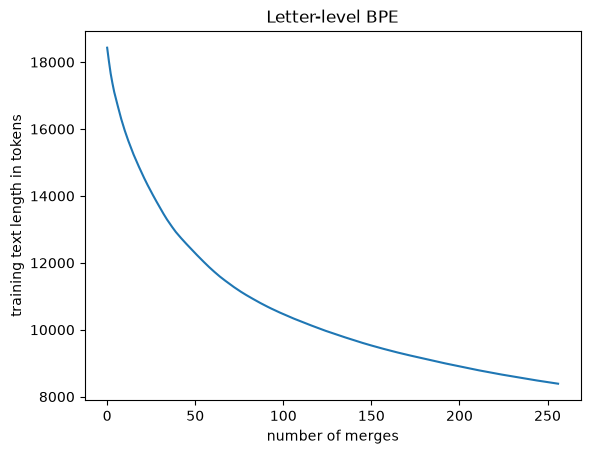

first 15 merges: [' t', 'he', ' a', 'in', ' h', ' s', ' w', ' o', ' the', 're', 'ou', 'it', 'is', ' m', 'ed']
longest tokens:  [' Gisburn', ' picture', ' Stroud', 'isburn', ' paint', ' Strou', ' about', ' could', ' that', ' with']


In [11]:
alphabet = sorted(set(train_text))                         # base vocabulary: characters
let_stoi = {c: i for i, c in enumerate(alphabet)}
train_chunks = re.findall(CHUNK, train_text)

t0 = time.perf_counter()
let_merges, let_lengths = train_bpe([[let_stoi[c] for c in ch] for ch in train_chunks],
                                    256, len(alphabet))
let_table = token_strings(alphabet, let_merges)
print(f"trained in {time.perf_counter() - t0:.1f} s; {len(alphabet)} distinct characters")
print(f"training text: {let_lengths[0]} characters -> {let_lengths[-1]} tokens after 256 merges")

def letter_encode(s):
    out = []
    for ch in re.findall(CHUNK, s):
        out += apply_merges([let_stoi[c] for c in ch], let_merges)   # KeyError for unknown characters
    return out

def letter_decode(ids):
    return "".join(let_table[i] for i in ids)

plt.plot(let_lengths)
plt.xlabel("number of merges")
plt.ylabel("training text length in tokens")
plt.title("Letter-level BPE")
plt.show()

new_tokens = list(let_merges.values())
print("first 15 merges:", [let_table[i] for i in new_tokens[:15]])
print("longest tokens: ", sorted((let_table[i] for i in new_tokens), key=len, reverse=True)[:10])

The Lecture 3 example gives the expected merges `l+o`, `lo+w`, `low+e`. On the training text the base vocabulary has **62** characters, and 256 merges shrink the 18,431 characters to **8,388** tokens. The first merges are ` t`, `he`, ` a`, as in the reference. The curve falls steeply at first and then flattens: the first merges replace the most frequent pairs (hundreds of occurrences each), and later merges only pay off for rarer pairs. The longest tokens are whole frequent words with their leading space (` Gisburn`, ` picture`, ` Stroud`, ` could`), so frequent words end up as single tokens.

In [12]:
print("round trip on the held-out text:", letter_decode(letter_encode(held_text)) == held_text)
for word in ["Łódź", "猫"]:
    try:
        letter_encode(word)
    except KeyError as e:
        print(f"{word!r}: KeyError {e} - the character is not in the base vocabulary")

round trip on the held-out text: True
'Łódź': KeyError 'Ł' - the character is not in the base vocabulary
'猫': KeyError '猫' - the character is not in the base vocabulary


On the held-out text the round trip works: every character there also occurs in training, and BPE only regroups characters without losing any (the chunks join back to the text exactly). `Łódź` and `猫` fail with a `KeyError`: `Ł` and `猫` never occur in the training text, so they are not in the base vocabulary and have no ID. This is the OOV problem of Task 3.2 again, one level lower: letter-level BPE has no OOV *words*, but it can still meet unknown *characters* (Materials 3.3).

### 3.4 From letters to bytes: byte-level BPE

- Replace the base vocabulary by the 256 UTF-8 byte values (merged tokens get IDs 256, 257, …; ties broken by the smaller pair of IDs); `decode` concatenates the bytes and then decodes UTF-8. Train on the same chunks with 256 merges (vocabulary size 512). Show that on this ASCII text the merges are the same as in Task 3.3, and that the round trip now works for any string, including `Łódź` and Chinese.
- Train your byte-level BPE with about 60 merges on a short text full of multi-byte characters, for example a few Polish and Chinese sentences of your choice. Classify each new token as ASCII, whole multi-byte character(s), part of one character, or crossing a character boundary, and show which characters end up as one token and which stay split into bytes. Relate what you see to Lecture 3, Q&A, Question 1.
- Compare your tokenizer with GPT-2's (`tiktoken`) on the held-out text and on a short Polish text: bytes per token, and whether `decode(encode(s)) == s`. Explain the difference between the two languages. Reference: GPT-2 encodes the whole text in 5145 tokens; on the held-out text your tokenizer gives about 2.3 bytes per token and GPT-2 about 3.8.
- Find a GPT-2 token whose bytes are not valid UTF-8 on their own, and show what decoding token by token does to it.
- Train on the training text as one chunk, without the split, and compare the learned merges and the compression. *(optional)*

**What I do** (background: Materials 3.4 — *Bytes, Unicode and UTF-8*, *Byte-level BPE*, *Decoding: concatenate the bytes, then decode UTF-8*, *How multi-byte characters get merged*, *Measuring compression*, *tiktoken*)

1. Reuse `train_bpe` and `apply_merges` from Task 3.3; only the base vocabulary changes: a chunk becomes `list(chunk.encode("utf-8"))`, IDs 0–255, new tokens 256, 257, …
2. `bpe_decode` builds the table ID → bytes in merge order, joins the bytes of all tokens with `b"".join` and decodes UTF-8 **once** at the end.
3. Compare the 256 byte-level merges with the 256 letter merges, and run the round trip on `Łódź` and Chinese.

In [13]:
def byte_table(merges):
    table = {i: bytes([i]) for i in range(256)}
    for (a, b), i in merges.items():
        table[i] = table[a] + table[b]
    return table

def bpe_encode(s, merges):
    out = []
    for ch in re.findall(CHUNK, s):
        out += apply_merges(list(ch.encode("utf-8")), merges)
    return out

def bpe_decode(ids, merges):
    table = byte_table(merges)
    return b"".join(table[i] for i in ids).decode("utf-8")   # join first, decode once

byte_merges, byte_lengths = train_bpe([list(ch.encode("utf-8")) for ch in train_chunks], 256, 256)
btab = byte_table(byte_merges)
same = [let_table[i] for i in let_merges.values()] == [btab[i].decode() for i in byte_merges.values()]
print("is the training text ASCII:", train_text.isascii())
print("same 256 merges as letter-level BPE:", same, "| tokens:", byte_lengths[-1])

for s in ["Łódź", "猫が好き", "Zażółć gęślą jaźń 👍🏽"]:
    ids = bpe_encode(s, byte_merges)
    print(f"{s!r}: {len(s.encode())} bytes -> {len(ids)} tokens, round trip: {bpe_decode(ids, byte_merges) == s}")

is the training text ASCII: True
same 256 merges as letter-level BPE: True | tokens: 8388
'Łódź': 7 bytes -> 7 tokens, round trip: True
'猫が好き': 12 bytes -> 12 tokens, round trip: True
'Zażółć gęślą jaźń 👍🏽': 35 bytes -> 33 tokens, round trip: True


The training text is pure ASCII, and for ASCII characters the byte value equals the code point. So the byte IDs sort in the same order as the characters, the pair counts are the same, and the ties are broken the same way: all **256 merges are identical** to those of Task 3.3, giving the same 8,388 tokens. Now the round trip works for any string, because every string is a sequence of bytes and all 256 bytes are in the base vocabulary. Text the merges have never seen (`Łódź`, Japanese, an emoji) simply takes more, shorter tokens, here close to one token per byte.

**Multi-byte characters.** I train 60 merges on a short Polish + Chinese text of my own and classify every new token by the byte roles of Materials 3.4 (`00–7F` ASCII, `80–BF` continuation, `C2–F4` lead):

- **ASCII**: all bytes < 0x80;
- **whole character(s)**: not ASCII, but strict `token.decode("utf-8")` works;
- **crosses a boundary**: strict decoding fails and a new character starts *inside* the token (a lead or ASCII byte after the first position);
- **part of one character**: strict decoding fails and no character starts inside it.

In [14]:
multi_text = ("Zażółć gęślą jaźń. Wrocław leży nad Odrą, a Kraków nad Wisłą. "
              "Łódź płynie po jeziorze, a żółw je źdźbło trawy. Dziś jest piękny dzień, "
              "więc idziemy na spacer nad Odrą. Żółta łódź płynie dziś do Wrocławia. "
              "我喜欢学习中文。中文很有意思。我们在大学学习语言模型。"
              "今天天气很好，我们去公园散步。我喜欢中文，也喜欢语言模型。")

multi_merges, _ = train_bpe([list(c.encode()) for c in re.findall(CHUNK, multi_text)], 60, 256)
mtab = byte_table(multi_merges)

def classify(tok):
    try:
        tok.decode("utf-8")
        return "ASCII" if tok.isascii() else "whole character(s)"
    except UnicodeDecodeError:
        starts_inside = any(b < 0x80 or b >= 0xC0 for b in tok[1:])
        return "crosses a boundary" if starts_inside else "part of one character"

groups = {}
for i in multi_merges.values():
    groups.setdefault(classify(mtab[i]), []).append(mtab[i])
for kind, toks in groups.items():
    readable = kind in ("ASCII", "whole character(s)")
    print(f"{kind} ({len(toks)}):", [t.decode() if readable else t.hex(" ") for t in toks][:12])

whole character(s) (19): ['ł', 'ó', 'ź', '。', 'ą', '我', 'dź', 'ę', 'ś', '喜', '学', '欢']
ASCII (16): ['zi', ' j', ' n', ' p', ' na', ' W', ' d', 'aw', ' je', ' nad', ' O', ' a']
part of one character (12): ['80 82', '88 91', '96 87', '96 9c', 'ac a2', 'ad a6', 'e4 b9', 'e4 bb', 'e5 a4', '9e 8b', 'bc 8c', 'be 88']
crosses a boundary (13): ['ad e6', '20 c5', 'ac e5', 'b8 ad e6', 'e4 b8 ad e6', '65 c5', '80 e6', 'a1 e5', 'a8 80 e6', 'a8 a1 e5', 'ad e8', 'af ad e8']


In [15]:
counts = Counter(c for c in multi_text if not c.isascii())
print("char  count  bytes  tokens when encoded alone")
for ch, n in counts.most_common():
    print(f"{ch:>3}  {n:5d}  {len(ch.encode()):5d}  {len(bpe_encode(ch, multi_merges)):5d}")

char  count  bytes  tokens when encoded alone
  ł     10      2      1
  ó      6      2      1
  ź      5      2      1
  。      5      3      1
  ą      4      2      1
  我      4      3      1
  ż      3      2      2
  ę      3      2      1
  ś      3      2      1
  喜      3      3      1
  欢      3      3      1
  学      3      3      1
  中      3      3      3
  文      3      3      2
  ń      2      2      2
  习      2      3      2
  很      2      3      2
  们      2      3      2
  语      2      3      3
  言      2      3      3
  模      2      3      3
  型      2      3      2
  天      2      3      2
  ，      2      3      2
  ć      1      2      2
  Ł      1      2      2
  Ż      1      2      2
  有      1      3      3
  意      1      3      3
  思      1      3      3
  在      1      3      3
  大      1      3      2
  今      1      3      2
  气      1      3      3
  好      1      3      3
  去      1      3      3
  公      1      3      3
  园      1      3      3
  散 

All four kinds of token appear, as in Lecture 3, Q&A, Question 1 (summarised in Materials 3.4). Merges are chosen by frequency only and the algorithm knows nothing about characters. **Frequent** multi-byte characters (`ł` 10×, `ó`, `ź`, `ą`, `我`, `。`) became one token each, and `dź` is even merged across two characters. **Rare** ones (`Ł`, `ć`, `Ż`, and most Chinese characters seen once or twice) stay split into 2–3 byte tokens. Some new tokens are only part of one character (`e4 b9` is a lead byte plus one continuation byte). Others **cross a character boundary**: `20 c5` is a space plus the first byte of `Ł`, and `e4 b8 ad e6` is `中` plus the first byte of the next character. The Chinese run has no spaces, so it is one chunk and merges can cross from one character to the next; Polish letters count as `\w` and stay inside their word's chunk. Tokens like these are not valid UTF-8 on their own.

**Comparison with GPT-2.** Bytes per token $M/N$ (Materials 3.4, *Measuring compression*) of my tokenizer (256 merges, $V = 512$) and of GPT-2 ($V = 50\,257$) on the held-out English text and on a short Polish text, plus the round trip. `encode_ordinary` encodes everything as plain text.

In [16]:
polish = ("Wrocław jest jednym z największych miast w Polsce. Leży nad Odrą, a jego "
          "historia sięga ponad tysiąca lat. Na rynku stoi gotycki ratusz, a w całym "
          "mieście można spotkać małe figurki krasnali, które stały się symbolem Wrocławia.")

print(f"GPT-2 tokens for the whole text: {len(enc.encode(text))}")
print("text        tokenizer   bytes/token   round trip")
for name, s in [("held-out", held_text), ("Polish", polish)]:
    M = len(s.encode("utf-8"))
    mine = bpe_encode(s, byte_merges)
    gpt = enc.encode_ordinary(s)
    print(f"{name:10s}  mine        {M / len(mine):6.2f}        {bpe_decode(mine, byte_merges) == s}")
    print(f"{name:10s}  GPT-2       {M / len(gpt):6.2f}        {enc.decode(gpt) == s}")

GPT-2 tokens for the whole text: 5145
text        tokenizer   bytes/token   round trip
held-out    mine          2.26        True
held-out    GPT-2         3.84        True
Polish      mine          1.32        True
Polish      GPT-2         2.03        True


GPT-2 needs **5145 tokens** for the whole text, as in the reference. On the English held-out text my tokenizer gives **2.26 bytes per token** and GPT-2 **3.84** (reference 2.3 and 3.8). Both are lossless (`True`). GPT-2 has 50,000 merges learned on a large English web corpus, against my 256 learned on 18,000 characters, so it has whole-word tokens for most English words. On Polish both compress much worse (1.32 and 2.03 bytes per token). Neither tokenizer's training data had much Polish, so its words and its two-byte letters (`ł`, `ą`, `ę`) are split into short pieces, sometimes single bytes. Coverage is never a problem with bytes, but efficiency is: the same content costs more tokens in Polish, so less text fits in the context window (Materials 3.4, *Consequence*).

In [17]:
# a merged GPT-2 token that is not valid UTF-8 on its own
for t in range(256, enc.n_vocab - 1):
    b = enc.decode_single_token_bytes(t)
    try:
        b.decode("utf-8")
    except UnicodeDecodeError:
        print(f"first such token: ID {t}, bytes {b.hex(' ')}")
        break

ids = enc.encode(" Łódź")
pieces = [enc.decode_single_token_bytes(t) for t in ids]
print("' Łódź' ->", ids, [p.hex(" ") for p in pieces])
print("token by token:", [p.decode("utf-8", errors="replace") for p in pieces])
print("joined first:  ", repr(b"".join(pieces).decode("utf-8")))

first such token: ID 447, bytes e2 80
' Łódź' -> [25370, 223, 10205, 67, 129, 118] ['20 c5', '81', 'c3 b3', '64', 'c5', 'ba']
token by token: [' �', '�', 'ó', 'd', '�', '�']
joined first:   ' Łódź'


Already GPT-2's token 447, bytes `e2 80`, is not valid UTF-8 on its own: it is the first two bytes of three-byte characters such as `’` (U+2019, `e2 80 99`), which are frequent in web text. In ` Łódź`, the token `20 c5` holds a space plus the lead byte of `Ł`, and `ź` is split into the two tokens `c5` and `ba`. Decoding token by token turns every incomplete piece into the replacement character `�` (` �`, `�`, `ó`, `d`, `�`, `�`), so the text is corrupted. Joining the bytes of all tokens first and decoding once gives back ` Łódź` exactly (Materials 3.4, *Decoding*).

*(optional)* **No chunks.** The same 256 byte-level merges trained on the training text as **one chunk**, so merges may cross word boundaries (Materials 3.3, *Chunks matter*).

In [18]:
one_merges, one_lengths = train_bpe([list(train_text.encode())], 256, 256)
otab = byte_table(one_merges)
crossing = [otab[i].decode() for i in one_merges.values() if " " in otab[i].decode().strip(" ")
            or otab[i].decode().endswith(" ")]
print("training text after 256 merges:  with chunks", byte_lengths[-1], "| one chunk", one_lengths[-1])
print("first 15 merges (one chunk):", [otab[i].decode() for i in list(one_merges.values())[:15]])
print(f"{len(crossing)} tokens span a word boundary, e.g.", crossing[:12])

training text after 256 merges:  with chunks 8388 | one chunk 8406
first 15 merges (one chunk): ['e ', ' t', 'd ', 't ', 'in', 's ', 'he ', ', ', 'er', 'ha', 'ou', 'on', 'an', 'en', ' the ']
108 tokens span a word boundary, e.g. ['e ', 'd ', 't ', 's ', 'he ', ', ', ' the ', 'y ', '. ', 'ed ', 'o ', 'I ']


Without chunks the merges are different from the start: the most frequent pair is now `e` + space (`e `), and many tokens span a word boundary. 108 of the 256 tokens contain a space that is not at the front (`he `, `, `, ` the `, `. `, `ed `). The space can now attach to the end of a word as well as the start, so the vocabulary is spent on many variants of the same word with different surrounding spaces or punctuation. Compression on the training text is almost the same (8,406 vs 8,388 tokens), but the tokens are less reusable: ` the` and ` the ` and `the ` are different entries. Chunking forces a consistent rule (a space belongs to the following word) and keeps merges inside words, which is why GPT-2 pre-tokenizes.

### 3.5 Comparing tokenizers with bits per byte

- Fit the add-$\alpha$ bigram model of List 1, Task 2.3, to token IDs instead of characters, for three tokenizers: bytes ($V = 256$) and your byte-level BPE with $V = 512$ and $V = 1024$ (default $\alpha = 0.1$). Fit on the first 90% and report, for each tokenizer, the per-token perplexity of the held-out text and its bits per byte $\mathrm{BPB} = N\bar\ell/(M\ln 2)$: $N$ held-out tokens with mean negative log-likelihood $\bar\ell$ (in nats), $M$ UTF-8 bytes of the held-out text.
- Explain why the two measures rank the tokenizers in opposite orders. Reference: perplexity about 11.5, 87 and 290; BPB about 3.53, 2.85 and 2.83.

**What I do** (background: Materials 3.5 — *Units of the loss*, *Perplexity depends on the tokenizer*, *Bits per byte*, *Scoring held-out text with a bigram model*)

1. Train byte-level BPE once with 768 merges; the merges with IDs below $V$ are exactly the tokenizer of size $V$ (each merge depends only on the earlier ones), so $V = 256$ (no merges), 512 and 1024 come from one run.
2. For each tokenizer: encode training and held-out text, count bigrams with `torch.bincount` as in List 1, add $\alpha = 0.1$ and normalise the rows.
3. Score **every** held-out token, using the last training token as the context of the first one, and sum the NLL: perplexity $= e^{\bar\ell}$, $\mathrm{BPB} = N\bar\ell / (M\ln 2)$ with the same $M$ (UTF-8 bytes of the held-out text) for all tokenizers.

In [19]:
def bigram_scores(merges, V, train_s, held_s, alpha=0.1):
    tr = torch.tensor(bpe_encode(train_s, merges))
    he = torch.tensor(bpe_encode(held_s, merges))
    counts = torch.bincount(tr[:-1] * V + tr[1:], minlength=V * V).view(V, V).float()
    P = (counts + alpha) / (counts + alpha).sum(dim=1, keepdim=True)
    seq = torch.cat([tr[-1:], he])                     # last training token = context of the first
    nll = -torch.log(P[seq[:-1], seq[1:]])              # one value per held-out token
    M = len(held_s.encode("utf-8"))
    return len(he), math.exp(nll.mean().item()), nll.sum().item() / (M * math.log(2))

big_merges, _ = train_bpe([list(ch.encode()) for ch in train_chunks], 768, 256)

print("   V   held-out tokens   bytes/token   perplexity    BPB")
M = len(held_text.encode("utf-8"))
for V in [256, 512, 1024]:
    merges_V = {p: i for p, i in big_merges.items() if i < V}
    N, ppl, bpb = bigram_scores(merges_V, V, train_text, held_text)
    print(f"{V:5d}   {N:15d}   {M / N:11.2f}   {ppl:10.1f}   {bpb:5.2f}")

   V   held-out tokens   bytes/token   perplexity    BPB
  256              2048          1.00         11.5    3.53
  512               906          2.26         87.4    2.85
 1024               709          2.89        289.9    2.83


The results match the reference: perplexity **11.5, 87, 290** and BPB **3.53, 2.85, 2.83** for $V = 256, 512, 1024$. **Perplexity** is per token, and larger tokens are harder to predict: a byte has only 256 possible values, many of them very predictable within a word, while a 1024-vocabulary token carries 2.9 bytes of text. So perplexity rises with $V$ and seems to favour bytes. **BPB** divides the total NLL by the same number of bytes $M$ for all tokenizers, so it measures how many bits the whole system needs to encode the same text. Larger tokens need far fewer predictions (709 instead of 2048), and the total cost falls: BPB prefers $V = 1024$. The gain from 512 to 1024 is small, because the bigram table with $V^2 = 10^6$ cells is very sparse and smoothing matters more.

### 3.6 Tokenization consequences *(optional)*

- With `tiktoken`, show how GPT-2 splits `strawberry` with and without a leading space, numbers such as `12345` and `1234 + 5678`, and repeated spaces. Relate what you see to the difficulties LLMs have with counting letters and with arithmetic.

**What I do** (background: Materials 3.6): print GPT-2's tokens for each string with `enc.decode_single_token_bytes`.

In [20]:
for s in ["strawberry", " strawberry", "12345", "1234 + 5678", "12345 + 67890",
          "a b", "a  b", "a    b"]:
    pieces = [enc.decode_single_token_bytes(t).decode("utf-8") for t in enc.encode(s)]
    print(f"{s!r:18s} {pieces}")

'strawberry'       ['st', 'raw', 'berry']
' strawberry'      [' strawberry']
'12345'            ['123', '45']
'1234 + 5678'      ['12', '34', ' +', ' 5', '678']
'12345 + 67890'    ['123', '45', ' +', ' 6', '78', '90']
'a b'              ['a', ' b']
'a  b'             ['a', ' ', ' b']
'a    b'           ['a', ' ', ' ', ' ', ' b']


` strawberry` with a leading space is one token, while `strawberry` without it is `st`+`raw`+`berry`. Either way the model never sees the letters as separate units. To count the `r`s it must have learned the spelling of each token indirectly, and the split differs depending on a space. Numbers are cut into chunks of up to three digits whose boundaries depend on the digits and on the space before them (`12345` → `123|45`, ` 5678` → ` 5|678`), so units, tens and hundreds don't line up across the two operands. Column-wise addition is therefore not what the model sees. Repeated spaces become extra space tokens (`a    b` → `a`, ` `, ` `, ` `, ` b`), so different whitespace means different IDs (Materials 3.6). This is an obstacle, not an impossibility; it is one of several causes of such errors.

- **Checkpoint:** your byte-level BPE (Task 3.4) gives `decode(encode(s)) == s` for every string in Materials, Appendix B (empty text, leading and repeated spaces, newlines, Polish, Japanese, an emoji with a skin-tone modifier, and the literal text `<|endoftext|>`).

Checkpoint from Materials, Appendix B, with my byte-level BPE (256 merges) from Task 3.4.

In [21]:
def check_roundtrip(encode, decode):
    strings = ["", " leading space", "repeated   spaces",
               "two\nlines\n\n", "Zażółć gęślą jaźń",
               "猫が好きです", "👍🏽 thumbs up", "<|endoftext|>"]
    for s in strings:
        assert decode(encode(s)) == s, f"round trip fails for {s!r}"
    print("Checkpoint Lab 3 passed")

check_roundtrip(lambda s: bpe_encode(s, byte_merges),
                lambda ids: bpe_decode(ids, byte_merges))

Checkpoint Lab 3 passed


## Lab 4

### 4.1 An embedding is a one-hot vector times a matrix

- Show numerically that `nn.Embedding(V, d)` gives the same outputs as a one-hot input times `nn.Linear(V, d, bias=False)` whose weight is the transposed embedding matrix, and the same gradients for the same loss. Show that only the rows of the tokens that were looked up get non-zero gradients.
- Time both for $V = 50257$, $d = 768$ and 256 token IDs. *(optional)*

**What I do** (background: Materials 4.1 — *The embedding matrix*, *nn.Embedding and nn.Linear store the matrix differently*, *Sparse gradients*, *Cost*)

1. `nn.Embedding(V, d)` stores $E \in \mathbb R^{V\times d}$; `nn.Linear(V, d, bias=False)` stores $W \in \mathbb R^{d\times V}$ and computes $XW^\top$. Copy $W = E^\top$ inside `torch.no_grad()`.
2. Feed the same IDs (one of them twice) as a lookup and as one-hot rows `F.one_hot(idx, V).float()`; compare the outputs.
3. Use the same loss (outputs times a fixed random tensor, summed), call `backward()` on both and compare `emb.weight.grad` with `lin.weight.grad.T`; list the rows with non-zero gradient.

In [22]:
torch.manual_seed(0)
V, d = 10, 4
emb = nn.Embedding(V, d)
lin = nn.Linear(V, d, bias=False)
with torch.no_grad():
    lin.weight.copy_(emb.weight.T)                        # W = E^T

idx = torch.tensor([3, 1, 3, 7])                          # token 3 occurs twice
out_emb = emb(idx)
out_lin = lin(F.one_hot(idx, num_classes=V).float())
print("same outputs:", torch.allclose(out_emb, out_lin))

w = torch.randn(len(idx), d)                              # the same loss for both
(out_emb * w).sum().backward()
(out_lin * w).sum().backward()
print("same gradients:", torch.allclose(emb.weight.grad, lin.weight.grad.T))
print("rows with non-zero gradient:", emb.weight.grad.abs().sum(dim=1).nonzero().flatten().tolist())
print("row 3 = sum of its two contributions:", torch.allclose(emb.weight.grad[3], w[0] + w[2]))

same outputs: True
same gradients: True
rows with non-zero gradient: [1, 3, 7]
row 3 = sum of its two contributions: True


The lookup and the one-hot product give the same outputs and the same gradients ($\partial L/\partial E = X^\top\, \partial L/\partial\text{out}$, Materials 4.1). Row $j$ of $X^\top$ has ones exactly where token $j$ occurs. So the rows of tokens that were not looked up get exactly zero gradient. A token that occurs once (1, 7) gets the gradient of its one output row, and a token that occurs twice (3) gets the **sum** of the gradients of both positions.

*(optional)* Timing for GPT-2's sizes, average of 20 runs.

In [23]:
V, d = 50257, 768
emb_big = nn.Embedding(V, d)
lin_big = nn.Linear(V, d, bias=False)
idx = torch.randint(0, V, (256,))

def avg_time(f, reps=20):
    f()                                                   # warm-up
    t0 = time.perf_counter()
    for _ in range(reps):
        f()
    return (time.perf_counter() - t0) / reps

with torch.no_grad():
    t_emb = avg_time(lambda: emb_big(idx))
    t_lin = avg_time(lambda: lin_big(F.one_hot(idx, V).float()))
print(f"lookup: {t_emb * 1e3:.3f} ms   one-hot @ W^T: {t_lin * 1e3:.1f} ms   ratio: {t_lin / t_emb:.0f}x")

lookup: 0.035 ms   one-hot @ W^T: 104.0 ms   ratio: 3005x


For GPT-2's sizes the lookup takes microseconds, while the one-hot product takes about 100 ms, several thousand times slower. The lookup only copies $T$ rows of length $d$ ($O(Td)$). The product first builds a $256 \times 50{,}257$ one-hot matrix and multiplies it by the whole $50{,}257 \times 768$ matrix ($O(TVd)$), almost all of it multiplications by zero. That is why every model uses the lookup. (The exact ratio depends on the CPU.)

### 4.2 Sliding-window samples

- Implement `create_dataloader`. Derive the number of windows for $N$ tokens, window length $L$ (`max_length`) and stride $s$, and check it against `len(loader.dataset)` for several $(L, s)$. Reference: the whole text with $L = s = 4$ gives 1286 windows.
- Print the first two input and target windows for stride 1 and for stride $L$, as tokens. Explain the overlap and why stride $L$ is a common default.

**What I do** (background: Materials 4.2 — *Inputs and targets for next-token prediction*, *Stride and overlap*, *Counting windows*, *A Dataset of windows*; exact specification in Appendix A)

1. A small `Dataset` class encodes the text once with GPT-2's tokenizer (allowing `<|endoftext|>`), and in `__init__` stores all windows: for every start `i in range(0, N - max_length, stride)` the input `ids[i : i + L]` and the target `ids[i + 1 : i + L + 1]` (shifted by one), as `int64` tensors.
2. `create_dataloader` wraps it in a `DataLoader` with the given batch size, shuffling, `drop_last` and `num_workers`.

**Number of windows.** The window starting at $i$ needs tokens up to $x_{i+L}$, so it exists iff $i + L + 1 \le N$, i.e. $i \le N - L - 1$. The starts are the multiples of $s$ in $[0,\, N-L-1]$: $0, s, \dots, ks$ with $k = \lfloor (N-L-1)/s \rfloor$, so

$$\#\text{windows} = \left\lfloor \frac{N - L - 1}{s} \right\rfloor + 1 \qquad (N \ge L + 1).$$

In [24]:
class WindowDataset(Dataset):
    def __init__(self, text, max_length, stride):
        ids = tiktoken.get_encoding("gpt2").encode(text, allowed_special={"<|endoftext|>"})
        self.inputs, self.targets = [], []
        for i in range(0, len(ids) - max_length, stride):
            self.inputs.append(torch.tensor(ids[i : i + max_length]))
            self.targets.append(torch.tensor(ids[i + 1 : i + max_length + 1]))   # shifted by one

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, j):
        return self.inputs[j], self.targets[j]


def create_dataloader(
    text: str,
    batch_size: int = 4,
    max_length: int = 256,
    stride: int = 128,
    shuffle: bool = True,
    drop_last: bool = True,
    num_workers: int = 0,
) -> DataLoader:
    """Next-token (inputs, targets) windows of GPT-2 token IDs.

    Batches have shape (batch_size, max_length); see Materials, Appendix A.
    """
    dataset = WindowDataset(text, max_length, stride)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      drop_last=drop_last, num_workers=num_workers)

In [25]:
N = len(enc.encode(text))
print(f"N = {N} tokens")
print("  L    s   formula   len(loader.dataset)")
for L, s in [(4, 4), (4, 1), (8, 3), (256, 128), (100, 250)]:
    loader = create_dataloader(text, max_length=L, stride=s, shuffle=False)
    print(f"{L:3d}  {s:3d}   {(N - L - 1) // s + 1:7d}   {len(loader.dataset):7d}")

N = 5145 tokens
  L    s   formula   len(loader.dataset)
  4    4      1286      1286
  4    1      5141      5141
  8    3      1713      1713
256  128        39        39
100  250        21        21


In [26]:
def show(x):
    return [enc.decode([t]) for t in x.tolist()]

L = 4
for s in [1, L]:
    ds = create_dataloader(text, max_length=L, stride=s, shuffle=False).dataset
    print(f"stride {s}:")
    for j in range(2):
        x, y = ds[j]
        print(f"  window {j}: input {show(x)}  target {show(y)}")

stride 1:
  window 0: input ['I', ' H', 'AD', ' always']  target [' H', 'AD', ' always', ' thought']
  window 1: input [' H', 'AD', ' always', ' thought']  target ['AD', ' always', ' thought', ' Jack']
stride 4:
  window 0: input ['I', ' H', 'AD', ' always']  target [' H', 'AD', ' always', ' thought']
  window 1: input [' thought', ' Jack', ' G', 'is']  target [' Jack', ' G', 'is', 'burn']


The formula $\lfloor (N-L-1)/s \rfloor + 1$ agrees with `len(loader.dataset)` for every $(L, s)$, including $s > L$. The whole text ($N = 5145$) with $L = s = 4$ gives **1286** windows, as in the reference. In every window the target is the input shifted by one token. **Stride 1** windows overlap by $L - 1 = 3$ tokens: window 1 is window 0 moved by one token, so each target appears in up to $L$ windows with different contexts. That gives many examples, but they are strongly correlated and an epoch takes $L$ times longer. **Stride $L$** tiles the text without overlap: window 1 starts where window 0 ended (` thought`), so every token is a target exactly once. That is the most data per epoch without repetition, which is why $s = L$ is a common default.

### 4.3 Token and positional embeddings

- Implement `GPTEmbedding`. Report its number of parameters for the GPT-2 small configuration (vocabulary 50257, context length 1024, $d = 768$) with `count_parameters` from List 1, and check it by hand. Reference: 39,383,808.
- Show that without the positional term, permuting the input tokens permutes the output vectors in the same way, and that with it the same token at two positions gets two different vectors.

**What I do** (background: Materials 4.3 — *Why positions are needed*, *Learned absolute positions (GPT-2)*, *Broadcasting*, *GPT-2 sizes*; attribute names `tok_emb`, `pos_emb` from Appendix A)

`forward` looks up the token embeddings, shape $(B, T, d)$, and the position embeddings of positions $0, \dots, T-1$ (`torch.arange(T, device=idx.device)`), shape $(T, d)$; adding them broadcasts the same position vectors over the batch: $h_t = E_{x_t,:} + P_{t,:}$.

In [27]:
class GPTEmbedding(nn.Module):
    """Token embedding plus learned absolute position embedding."""

    def __init__(self, vocab_size: int, context_length: int, emb_dim: int):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, emb_dim)
        self.pos_emb = nn.Embedding(context_length, emb_dim)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        """(B, T) token IDs with T <= context_length -> (B, T, emb_dim)."""
        T = idx.shape[1]
        positions = torch.arange(T, device=idx.device)
        return self.tok_emb(idx) + self.pos_emb(positions)   # (B, T, d) + (T, d)

In [28]:
def count_parameters(model: nn.Module, trainable_only: bool = True) -> int:
    # from List 1, Task 1.4
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

gpt2_emb = GPTEmbedding(50257, 1024, 768)
print("count_parameters:", count_parameters(gpt2_emb))
print("by hand (V + T_max) * d:", (50257 + 1024) * 768)

count_parameters: 39383808
by hand (V + T_max) * d: 39383808


The GPT-2 small embedding layer has $(V + T_{\max})\,d = (50{,}257 + 1{,}024) \cdot 768 = $ **39,383,808** parameters, as in the reference. Most of it is the token table ($38.6$M); the position table adds only $0.8$M. That is almost a third of GPT-2 small's 124M parameters.

In [29]:
torch.manual_seed(0)
emb = GPTEmbedding(vocab_size=100, context_length=8, emb_dim=16)
idx = torch.tensor([[5, 17, 42, 5, 99]])                 # token 5 at positions 0 and 3
perm = torch.tensor([4, 2, 0, 3, 1])

# without the positional term: only the token embedding
tok = emb.tok_emb
print("tokens only, permuting the input permutes the output:",
      torch.equal(tok(idx[:, perm]), tok(idx)[:, perm]))

# with the positional term
out = emb(idx)
print("with positions, permutation equivariance holds:",
      torch.allclose(emb(idx[:, perm]), out[:, perm]))
print("token 5 at positions 0 and 3, tokens only - same vector:", torch.equal(tok(idx)[0, 0], tok(idx)[0, 3]))
print("token 5 at positions 0 and 3, with positions - same vector:", torch.equal(out[0, 0], out[0, 3]))

tokens only, permuting the input permutes the output: True
with positions, permutation equivariance holds: False
token 5 at positions 0 and 3, tokens only - same vector: True
token 5 at positions 0 and 3, with positions - same vector: False


The token embedding acts on each position separately, so permuting the input tokens permutes the output vectors in exactly the same way (permutation equivariance, Materials 4.3). The same token always gets the same vector: token 5 at positions 0 and 3 is identical. With the position embedding added, $h_t = E_{x_t} + P_t$ depends on $t$: equivariance no longer holds, and token 5 at positions 0 and 3 gets two different vectors. This is how the order becomes visible to the attention layers of List 3, which are themselves permutation-equivariant (`dog bites man` vs `man bites dog`).

### 4.4 Sinusoidal positional encodings

- Implement the sinusoidal encoding of Vaswani et al. (Materials 4.4) and show it as a heatmap for $T = 100$ positions and $d = 64$.
- Plot $\mathrm{PE}(t)\cdot\mathrm{PE}(t+k)$ against $k = 0, \dots, 50$ for several $t$. Explain why the curves coincide and why they start at $d/2$.
- Build the block-diagonal matrix $R(k)$ and check in `float64` that $\mathrm{PE}(t+k) = R(k)\,\mathrm{PE}(t)$ for all $t$ and several $k$.

**What I do** (background: Materials 4.4 — *A fixed function of the position*, *Dot products depend only on the offset*, *Shifting by k is a rotation*)

1. $\omega_i = 10000^{-2i/d}$ for $i = 0,\dots,d/2-1$; the column of positions $(T,1)$ times the row of frequencies $(d/2,)$ broadcasts to all angles $\omega_i t$, shape $(T, d/2)$; sines go to the even columns `pe[:, 0::2]`, cosines to the odd ones `pe[:, 1::2]`. Everything in `float64`.
2. Heatmap for $T = 100$, $d = 64$.
3. Plot $\mathrm{PE}(t)\cdot\mathrm{PE}(t+k)$ for $k = 0..50$ and $t \in \{0, 10, 30, 60\}$.
4. Build $R(k)$ with `torch.block_diag` from the $d/2$ blocks derived below, and check $\mathrm{PE}(t+k) = R(k)\,\mathrm{PE}(t)$ for all $t$ (rows of `pe`: `pe @ R.T`).

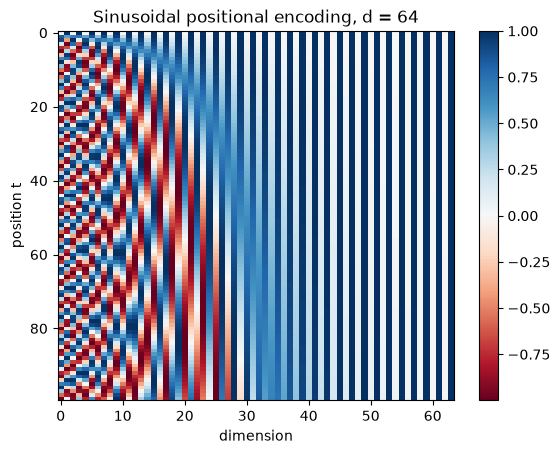

In [30]:
def sinusoidal_pe(T, d):
    t = torch.arange(T, dtype=torch.float64).unsqueeze(1)        # (T, 1)
    omega = 10000.0 ** (-torch.arange(0, d, 2, dtype=torch.float64) / d)   # (d/2,) = 10000^(-2i/d)
    pe = torch.zeros(T, d, dtype=torch.float64)
    pe[:, 0::2] = torch.sin(t * omega)                            # even dimensions: sin
    pe[:, 1::2] = torch.cos(t * omega)                            # odd dimensions: cos
    return pe

T, d = 100, 64
pe = sinusoidal_pe(T, d)
plt.imshow(pe, aspect="auto", cmap="RdBu")
plt.colorbar()
plt.xlabel("dimension")
plt.ylabel("position t")
plt.title("Sinusoidal positional encoding, d = 64")
plt.show()

Each column pair is a sine and a cosine of the position with frequency $\omega_i = 10000^{-2i/d}$. The left columns ($\omega_0 = 1$, wavelength $2\pi$) change sign every few positions, and the frequency falls from left to right. The right columns have wavelengths of thousands of positions and barely change over 100 positions (sine ≈ 0, cosine ≈ 1, hence the alternating white/blue stripes). Like the hands of a clock, the fast pairs tell neighbouring positions apart and the slow ones distant positions.

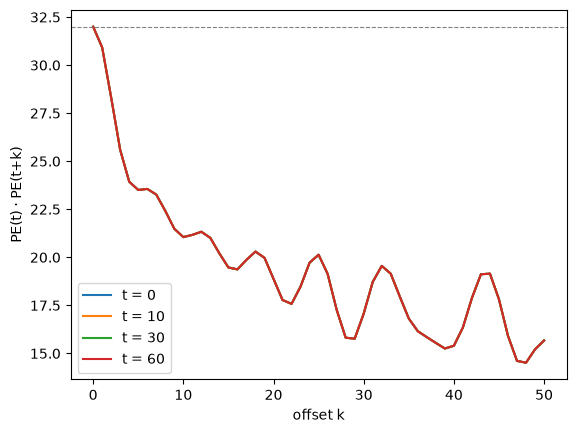

In [31]:
pe_long = sinusoidal_pe(200, d)
ks = range(51)
for t in [0, 10, 30, 60]:
    plt.plot(ks, [(pe_long[t] @ pe_long[t + k]).item() for k in ks], label=f"t = {t}")
plt.axhline(d / 2, color="gray", lw=0.8, ls="--")
plt.xlabel("offset k")
plt.ylabel("PE(t) · PE(t+k)")
plt.legend()
plt.show()

For one pair, $\sin(\omega_i t)\sin(\omega_i(t+k)) + \cos(\omega_i t)\cos(\omega_i(t+k)) = \cos(\omega_i k)$ by $\cos(a-b) = \cos a\cos b + \sin a \sin b$. Summing over the pairs gives $\mathrm{PE}(t)\cdot\mathrm{PE}(t+k) = \sum_{i=0}^{d/2-1}\cos(\omega_i k)$, which **does not depend on $t$**: the four curves lie exactly on top of each other (only the last one is visible). At $k = 0$ every term is $\cos 0 = 1$, so the curve starts at $d/2 = 32$ ($= \lVert\mathrm{PE}(t)\rVert^2$, since each pair has $\sin^2 + \cos^2 = 1$). It then falls as the fast pairs decorrelate, with bumps where some frequencies come back into phase. Nearby positions are more similar than distant ones.

In [32]:
def rotation(k, d):
    omega = 10000.0 ** (-torch.arange(0, d, 2, dtype=torch.float64) / d)
    blocks = [torch.tensor([[math.cos(w * k), math.sin(w * k)],
                            [-math.sin(w * k), math.cos(w * k)]], dtype=torch.float64)
              for w in omega.tolist()]
    return torch.block_diag(*blocks)                          # (d, d)

for k in [1, 5, 17, 50]:
    R = rotation(k, d)
    err = (pe[:-k] @ R.T - pe[k:]).abs().max().item()          # all t at once
    print(f"k = {k:2d}: max |R(k) PE(t) - PE(t+k)| = {err:.1e}")

k =  1: max |R(k) PE(t) - PE(t+k)| = 1.1e-14
k =  5: max |R(k) PE(t) - PE(t+k)| = 1.4e-14
k = 17: max |R(k) PE(t) - PE(t+k)| = 7.1e-15
k = 50: max |R(k) PE(t) - PE(t+k)| = 7.0e-15


From the angle-addition formulas with $a = \omega_i t$, $b = \omega_i k$: $\begin{pmatrix}\sin\omega_i(t+k)\\ \cos\omega_i(t+k)\end{pmatrix} = \begin{pmatrix}\cos\omega_i k & \sin\omega_i k\\ -\sin\omega_i k & \cos\omega_i k\end{pmatrix}\begin{pmatrix}\sin\omega_i t\\ \cos\omega_i t\end{pmatrix}$. The $2\times2$ block is a rotation that depends only on $k$, and $R(k)$ has the $d/2$ blocks on its diagonal. In `float64` the maximum error over all $t$ is about $10^{-14}$, i.e. rounding only, so $\mathrm{PE}(t+k) = R(k)\,\mathrm{PE}(t)$ holds exactly. A shift in position is a linear map that does not depend on the starting position, the property RoPE builds on (Materials 4.4).

### 4.5 Skip-gram with negative sampling *(optional)*

- Train skip-gram with negative sampling (Materials 4.5) on the words of the default text and print the nearest neighbours, by cosine similarity, of a few frequent words. Comment on what a text of a few thousand words can and cannot teach.

**What I do** (background: Materials 4.5 — *The skip-gram model*, *Negative sampling*, *Nearest neighbours*)

1. Words: lower-case letter runs of the text; all pairs (centre $w$, context $o$) at distance at most $c = 2$.
2. Two `nn.Embedding(V, 30)` tables, $u$ (centre) and $v$ (context), initialised small. For each batch draw $K = 5$ noise words per pair from $P_n \propto \text{count}^{3/4}$ with `torch.multinomial` and minimise $-\log\sigma(u_w^\top v_o) - \sum_k \log\sigma(-u_w^\top v_{n_k})$ with Adam.
3. Use $u + v$ as the word vectors (a common variant; the neighbours were similar but noisier with $u$ alone), normalise the rows and print the 5 nearest neighbours by cosine similarity of a few frequent words.

In [33]:
words = re.findall(r"[a-z]+", text.lower())
wvocab = sorted(set(words))
w2i = {w: i for i, w in enumerate(wvocab)}
wid = torch.tensor([w2i[w] for w in words])
c, K, dim = 2, 5, 30

centre = torch.cat([wid[:-j] for j in range(1, c + 1)] + [wid[j:] for j in range(1, c + 1)])
context = torch.cat([wid[j:] for j in range(1, c + 1)] + [wid[:-j] for j in range(1, c + 1)])
noise = torch.bincount(wid, minlength=len(wvocab)).float() ** 0.75
print(f"{len(words)} words, {len(wvocab)} distinct, {len(centre)} (centre, context) pairs")

torch.manual_seed(0)
u = nn.Embedding(len(wvocab), dim)
v = nn.Embedding(len(wvocab), dim)
nn.init.normal_(u.weight, std=0.1)
nn.init.normal_(v.weight, std=0.1)
opt = torch.optim.Adam(list(u.parameters()) + list(v.parameters()), lr=0.005)
loader = DataLoader(torch.utils.data.TensorDataset(centre, context), batch_size=256, shuffle=True)

for epoch in range(10):
    for w_b, o_b in loader:
        n_b = torch.multinomial(noise, len(w_b) * K, replacement=True).view(len(w_b), K)
        uw = u(w_b)                                                   # (B, dim)
        pos = (uw * v(o_b)).sum(-1)                                   # (B,)
        neg = (uw.unsqueeze(1) * v(n_b)).sum(-1)                      # (B, K)
        loss = -(F.logsigmoid(pos) + F.logsigmoid(-neg).sum(-1)).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
print("final batch loss:", round(loss.item(), 3))

E = F.normalize((u.weight + v.weight).detach(), dim=1)        # u + v, rows of length 1
for w in ["he", "she", "had", "his", "her", "picture", "the", "i"]:
    sims = E @ E[w2i[w]]
    best = sims.topk(6).indices[1:]                                   # skip the word itself
    print(f"{w:9s} ({Counter(words)[w]:3d}x):", [wvocab[i] for i in best])

3826 words, 1073 distinct, 15298 (centre, context) pairs
final batch loss: 2.027
he        ( 79x): ['lay', 'remained', 'indifferent', 'while', 'just']
she       ( 29x): ['did', 'after', 'thought', 'liked', 'idea']
had       ( 55x): ['mourned', 'dragged', 'existed', 'lingered', 'surrounded']
his       ( 65x): ['bed', 'own', 'forehead', 'clasping', 'laid']
her       ( 21x): ['husband', 'perceptible', 'enough', 'stay', 'spaniel']
picture   ( 11x): ['above', 'the', 'frame', 'weekly', 'virtuosity']
the       (184x): ['becoming', 'place', 'frame', 'above', 'bath']
i         (122x): ['simply', 'felt', 'hostess', 'could', 'am']


The neighbours are noisy, as the materials warn. They mostly reflect **which words appeared together in the same few phrases**, not similarity of meaning or grammatical role: `picture` → `frame`, `above` (the picture above the mantel), `her` → `husband`, `his` → `own`, `forehead`, and `he` and `she` are *not* each other's neighbours. word2vec needs many different contexts per word to learn that words used in the same way get similar vectors (the distributional hypothesis). With 3,826 words most words occur only once or twice, so each vector is shaped by a handful of pairs and partly by the random negatives. A text of a few thousand words can teach local co-occurrence, but not reliable semantic or grammatical classes; that takes millions to billions of words.

### 4.6 Your own experiment *(optional)*

About one hour of work: one question this list raised, answered with one plot or table and a paragraph. Ideas are in Materials 4.6.

**Question** (second idea of Materials 4.6): how does the BPB of the add-$\alpha$ bigram model (Task 3.5) depend on the vocabulary size of the byte-level BPE, where is the best size, and does it move when the training text is shorter?

**What I do:** for two training sets — the first 45% and the first 90% of the text — train byte-level BPE once to $V = 2048$ and, for $V \in \{256, 320, 384, 512, 768, 1024, 1536, 2048\}$, fit the bigram ($\alpha = 0.1$) on that training set and score the same held-out last 10% with `bigram_scores` from Task 3.5.

train on 45%: best V = 512, BPB = 3.401;   256: 3.72, 320: 3.48, 384: 3.42, 512: 3.40, 768: 3.47, 1024: 3.52, 1536: 3.57, 2048: 3.66
train on 90%: best V = 1024, BPB = 2.832;   256: 3.53, 320: 3.10, 384: 2.93, 512: 2.85, 768: 2.85, 1024: 2.83, 1536: 2.86, 2048: 2.90


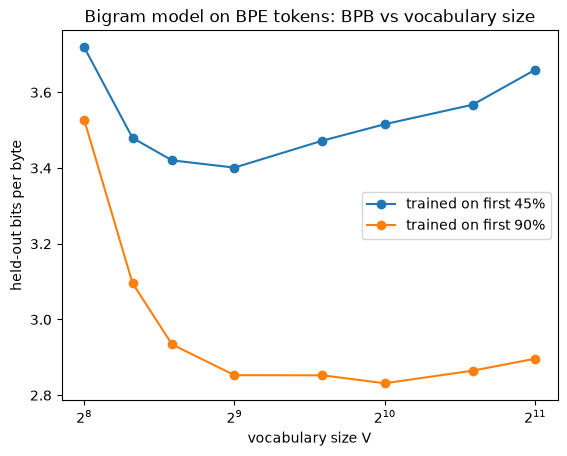

In [34]:
sizes = [256, 320, 384, 512, 768, 1024, 1536, 2048]
for frac in [0.45, 0.9]:
    tr_s = text[: int(frac * len(text))]
    m_all, _ = train_bpe([list(ch.encode()) for ch in re.findall(CHUNK, tr_s)], 2048 - 256, 256)
    bpbs = [bigram_scores({p: i for p, i in m_all.items() if i < V}, V, tr_s, held_text)[2]
            for V in sizes]
    best = sizes[bpbs.index(min(bpbs))]
    print(f"train on {frac:.0%}: best V = {best}, BPB = {min(bpbs):.3f};  ",
          ", ".join(f"{V}: {b:.2f}" for V, b in zip(sizes, bpbs)))
    plt.plot(sizes, bpbs, "o-", label=f"trained on first {frac:.0%}")
plt.xscale("log", base=2)
plt.xlabel("vocabulary size V")
plt.ylabel("held-out bits per byte")
plt.legend()
plt.title("Bigram model on BPE tokens: BPB vs vocabulary size")
plt.show()

BPB first falls quickly with $V$: merges replace many predictions of easy bytes by fewer predictions of larger tokens, and the bigram context (one previous token) then covers more text. At some point it rises again: the bigram table has $V^2$ cells, and with more tokens each pair is seen less often, so the counts get sparse and the smoothing dominates. With the first 45% of the text the best size is **$V = 512$** (BPB 3.40); with the first 90% it moves to **$V = 1024$** (BPB 2.83), and the whole curve is lower and flatter. More training text supports a larger vocabulary, because the extra counts fill more of the table. The best vocabulary size is a trade-off between shorter sequences and sparser statistics, and it grows with the data.

- **Checkpoint:** a batch from `create_dataloader(text, batch_size=8, max_length=4, stride=4, shuffle=False)` passed through `GPTEmbedding(50257, 4, 256)` has shape `(8, 4, 256)`, and its targets are its inputs shifted by one (code in Materials, Appendix B).

Contract check from Materials, Appendix A, then the Lab 4 checkpoint from Appendix B.

In [35]:
_text = ("Hello, Warsaw! " * 30 + "<|endoftext|>"
         + " Zażółć gęślą jaźń." * 10)
_enc = tiktoken.get_encoding("gpt2")
_ids = _enc.encode(_text, allowed_special={"<|endoftext|>"})
_N = len(_ids)
for _L, _s in [(4, 4), (8, 3), (16, 16)]:
    _loader = create_dataloader(_text, batch_size=2, max_length=_L,
                                stride=_s, shuffle=False,
                                drop_last=False)
    assert len(_loader.dataset) == (_N - _L - 1) // _s + 1, "windows"
    _x, _y = _loader.dataset[1]
    assert _x.dtype == torch.long, "token IDs must be int64"
    assert _x.tolist() == _ids[_s : _s + _L], "window 1 starts at s"
    assert _y.tolist() == _ids[_s + 1 : _s + _L + 1], "shift by one"
    _xb, _yb = next(iter(_loader))
    assert _xb.shape == _yb.shape == (2, _L)
_loader = create_dataloader(_text, batch_size=4, max_length=4,
                            stride=4)
assert len(_loader) == ((_N - 5) // 4 + 1) // 4, "drop_last"

_emb = GPTEmbedding(vocab_size=100, context_length=8, emb_dim=16)
assert isinstance(_emb.tok_emb, nn.Embedding)
assert isinstance(_emb.pos_emb, nn.Embedding)
assert tuple(_emb.tok_emb.weight.shape) == (100, 16)
assert tuple(_emb.pos_emb.weight.shape) == (8, 16)
assert sum(p.numel() for p in _emb.parameters()) == 100 * 16 + 8 * 16
_gen = torch.Generator().manual_seed(0)
_idx = torch.randint(0, 100, (3, 5), generator=_gen)
_out = _emb(_idx)
assert _out.shape == (3, 5, 16)
_pos = _emb.pos_emb.weight[:5]
assert torch.allclose(_out, _emb.tok_emb(_idx) + _pos)
_full = torch.zeros(1, 8, dtype=torch.long)
assert _emb(_full).shape == (1, 8, 16), "T = context_length must work"
print("Contract check passed: create_dataloader, GPTEmbedding")

Contract check passed: create_dataloader, GPTEmbedding


In [36]:
loader = create_dataloader(text, batch_size=8, max_length=4, stride=4,
                           shuffle=False)
inputs, targets = next(iter(loader))
emb = GPTEmbedding(50257, 4, 256)
assert inputs.shape == targets.shape == (8, 4)
assert inputs.dtype == torch.long
assert torch.equal(targets[:, :-1], inputs[:, 1:])
assert emb(inputs).shape == (8, 4, 256)
print("Checkpoint Lab 4 passed")

Checkpoint Lab 4 passed
